# Tasks 3 y 4 — Recomendación de camas y efecto de la epidemia
Hospital Regional del Altiplano · CC2017 · Grupo 3. Este notebook es autocontenido (no usa Drive): redefine las funciones de los notebooks 01–05 que necesita.

In [1]:
# --- Parámetros del grupo (mismo bloque de los notebooks anteriores) ---
import math, heapq, itertools
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import deque
from scipy import stats

g = 3
mu = 0.25                                  # tasa de salida por día (estancia media 1/mu = 4 d)
lam = 3.0 + 0.2 * ((g - 1) % 5)            # llegadas por día
c = 17 + ((g - 1) % 3)                     # camas actuales
a = lam / mu                               # carga ofrecida a = lambda/mu
rho = a / c
k_off = math.ceil(c - a) + 3               # camas fuera de servicio durante el cierre
Tb = 7                                     # días de cierre
beta = 0.30 + 0.02 * ((g - 1) % 4)         # contagio del SIR (Task 4)
print(f"Grupo {g}: lambda={lam:.1f}/día, c={c}, a={a:.2f}, rho={rho:.4f}, k_off={k_off}, Tb={Tb} d, beta={beta:.2f}")

Grupo 3: lambda=3.4/día, c=19, a=13.60, rho=0.7158, k_off=9, Tb=7 d, beta=0.34


In [2]:
# --- Teoría (Task 1.1) ---
def erlang_b(c, a):
    """Recurrencia de Erlang B: B(0)=1; B(k) = a B(k-1) / (k + a B(k-1))."""
    B = 1.0
    for k in range(1, c + 1):
        B = a * B / (k + a * B)
    return B

def theory_wait(lam, mu, c):
    """M/M/c: C(c,a) = B / (1 - rho (1-B)); Lq = C rho/(1-rho); Wq = Lq/lambda (Little)."""
    a = lam / mu; rho = a / c
    B = erlang_b(c, a); C = B / (1 - rho * (1 - B))
    Lq = C * rho / (1 - rho)
    return dict(C=C, Lq=Lq, Wq_h=Lq / lam * 24)

def ci95(x):
    """IC 95 % con t de Student; la unidad de muestreo es la RÉPLICA (punto ii del Task 1.3)."""
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    m = x.mean(); h = stats.t.ppf(.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return m, h

In [3]:
# --- Simulador validado en los Tasks 1-2 (versión mínima de simulate2: solo lo que usa el Task 3.1) ---
def make_stay(dist, mean, cs, rng):
    """Estancia con media `mean` y coeficiente de variación `cs`; lognormal: s^2=ln(1+cs^2), m=ln(mean)-s^2/2."""
    if dist == 'det':  return lambda: mean
    if dist == 'exp':  return lambda: rng.exponential(mean)
    if dist == 'logn':
        s2 = np.log(1 + cs**2); m = np.log(mean) - s2 / 2
        return lambda: rng.lognormal(m, np.sqrt(s2))
    raise ValueError(dist)

def simulate2(lam, c, T, warmup=0.0, seed=None, wait=True, stay_mean=4.0, dist='exp', cs=1.0):
    """DES con lista de eventos (heap). wait=True: M/G/c FIFO; wait=False: M/G/c/c (bloqueo)."""
    rng = np.random.default_rng(seed); sv = make_stay(dist, stay_mean, cs, rng)
    ev, cnt = [], itertools.count()
    def push(t, k, d=None): heapq.heappush(ev, (t, next(cnt), k, d))
    push(rng.exponential(1 / lam), 'A'); push(T, 'END')
    if warmup > 0: push(warmup, 'WARM')
    busy, q = 0, deque(); meas = warmup <= 0; last = 0.0
    aLq = 0.0; n_arr = n_blk = n_del = 0; waits = []
    def admit(t, a_t, cn):
        nonlocal busy
        busy += 1
        if cn: waits.append(t - a_t)                 # espera medida desde la LLEGADA
        push(t + sv(), 'D', (a_t, cn))
    while ev:
        t, _, k, d = heapq.heappop(ev)
        if k == 'END':
            if meas: aLq += len(q) * (T - last)      # promedio ponderado por duración del tramo
            break
        if meas: aLq += len(q) * (t - last)
        last = t
        if k == 'WARM': meas = True
        elif k == 'A':
            push(t + rng.exponential(1 / lam), 'A'); cn = meas; n_arr += cn
            if busy < c: admit(t, t, cn)
            elif wait: n_del += cn; q.append((t, cn))
            else: n_blk += cn                        # desviado a otro hospital
        else:
            busy -= 1
            while q and busy < c:
                a_t, cn = q.popleft(); admit(t, a_t, cn)
    span = T - warmup
    return dict(Lq=aLq / span, Pwait=n_del / n_arr if wait else 0.0,
                Pblock=n_blk / n_arr if not wait else 0.0, Wq=float(np.mean(waits)) if waits else np.nan)

def run_reps2(R, master_seed, **kw):
    """R réplicas con semillas independientes (SeedSequence.spawn)."""
    return [simulate2(seed=s, **kw) for s in np.random.SeedSequence(master_seed).spawn(R)]

## Task 3.1a — Menor número de camas que cumple cada meta
Metas de la directora: sin espera, $B(c,a)\le 2\,\%$; con espera, $W_q\le 6$ h. Se busca con la teoría (Erlang B y Erlang C) y se verifica con simulación (30 réplicas, T = 10 000 d, calentamiento 100 d).

In [4]:
def min_beds_block(lam, mu, goal=0.02):
    A = lam / mu
    return next(k for k in range(1, 200) if erlang_b(k, A) <= goal)

def min_beds_wait(lam, mu, goal_h=6.0, factor=1.0):
    """factor = (1+Cs^2)/2 de Allen-Cunneen (1 para M/M/c)."""
    A = lam / mu
    return next(k for k in range(int(A) + 1, 200) if theory_wait(lam, mu, k)['Wq_h'] * factor <= goal_h)

cB, cW = min_beds_block(lam, mu), min_beds_wait(lam, mu)
print("Teoría -> sin espera (B<=2%):", cB, " | con espera (Wq<=6 h):", cW)
rows = []
for cc in range(cW - 1, cW + 2):
    t_ = theory_wait(lam, mu, cc)
    r = run_reps2(30, 10 + cc, lam=lam, c=cc, T=10000.0, warmup=100.0, wait=True)
    m, h = ci95([x['Wq'] * 24 for x in r]); pw = np.mean([x['Pwait'] for x in r])
    rows.append(dict(variante="con espera", camas=cc, meta="Wq<=6 h", teoria=t_['Wq_h'], sim=m, IC_low=m - h, IC_high=m + h,
                     cumple_sim=(m + h) <= 6 or m <= 6, P_esperar=pw, espera_si_espera_h=24 / (cc * mu - lam)))
for cc in range(cB - 1, cB + 2):
    r = run_reps2(30, 50 + cc, lam=lam, c=cc, T=10000.0, warmup=100.0, wait=False)
    m, h = ci95([x['Pblock'] for x in r]); th = erlang_b(cc, a)
    rows.append(dict(variante="sin espera", camas=cc, meta="B<=2%", teoria=th, sim=m, IC_low=m - h, IC_high=m + h,
                     cumple_sim=m <= 0.02, P_esperar=np.nan, espera_si_espera_h=np.nan))
tab31a = pd.DataFrame(rows); tab31a.round(4)

Teoría -> sin espera (B<=2%): 21  | con espera (Wq<=6 h): 18


,variante,camas,meta,teoria,sim,IC_low,IC_high,cumple_sim,P_esperar,espera_si_espera_h
0,con espera,17,Wq<=6 h,8.2307,8.0238,7.5059,8.5418,False,0.2921,28.2353
1,con espera,18,Wq<=6 h,4.1517,4.1188,3.9215,4.3161,True,0.1909,21.8182
2,con espera,19,Wq<=6 h,2.1396,2.1729,2.0652,2.2806,True,0.1209,17.7778
3,sin espera,20,B<=2%,0.0248,0.0246,0.0241,0.0251,False,NaN,NaN
4,sin espera,21,B<=2%,0.0158,0.0158,0.0153,0.0163,True,NaN,NaN
5,sin espera,22,B<=2%,0.0097,0.0095,0.0091,0.0099,True,NaN,NaN


**Lectura.** Con espera basta $c=18$ (4.15 h), pero esa media esconde que ~19 % de los pacientes espera y quien espera lo hace ≈22 h (`espera_si_espera_h`). Sin espera se necesitan $c=21$ ($B=1.58\,\%$). Recomendación explícita en el reporte.

## Task 3.1b — Robustez en tres escenarios
(i) estancia +25 % ($\mu'=0.2$), (ii) llegadas +15 % ($\lambda'=1.15\lambda$), (iii) $C_S=2$ con la misma media. Para $C_S=2$ la teoría de bloqueo no cambia (Erlang B es insensible a la forma de la distribución del servicio, solo depende de la media); para la espera se usa Allen–Cunneen y se confirma con simulación lognormal.

In [5]:
scen = {"base": dict(lam=lam, mu=mu, cs=1.0), "(i) estancia +25 %": dict(lam=lam, mu=mu / 1.25, cs=1.0),
        "(ii) llegadas +15 %": dict(lam=lam * 1.15, mu=mu, cs=1.0), "(iii) Cs = 2": dict(lam=lam, mu=mu, cs=2.0)}
rows = []
for nm, p in scen.items():
    f = (1 + p['cs']**2) / 2
    rows.append(dict(escenario=nm, a=p['lam'] / p['mu'], camas_sin_espera_teoria=min_beds_block(p['lam'], p['mu']),
                     camas_con_espera_teoria=min_beds_wait(p['lam'], p['mu'], factor=f)))
rob = pd.DataFrame(rows).set_index('escenario'); rob

,a,camas_sin_espera_teoria,camas_con_espera_teoria
escenario,,,
base,13.60,21,18
(i) estancia +25 %,17.00,25,22
(ii) llegadas +15 %,15.64,23,20
(iii) Cs = 2,13.60,21,19


In [6]:
# Verificación por simulación de cada fila (el número propuesto debe cumplir y el anterior no)
dist_of = lambda cs: ('exp', 1.0) if cs == 1.0 else ('logn', cs)
ver = []
for nm, p in scen.items():
    d, cs_ = dist_of(p['cs']); sm = 1 / p['mu']
    n_w = rob.loc[nm, 'camas_con_espera_teoria']; n_b = rob.loc[nm, 'camas_sin_espera_teoria']
    for cc in (n_w - 1, n_w):
        r = run_reps2(30, 700 + cc, lam=p['lam'], c=cc, T=10000.0, warmup=100.0, wait=True, stay_mean=sm, dist=d, cs=cs_)
        m, h = ci95([x['Wq'] * 24 for x in r]); ver.append((nm, "con espera", cc, f"{m:.2f} ± {h:.2f} h", m <= 6))
    for cc in (n_b - 1, n_b):
        r = run_reps2(30, 900 + cc, lam=p['lam'], c=cc, T=10000.0, warmup=100.0, wait=False, stay_mean=sm, dist=d, cs=cs_)
        m, h = ci95([x['Pblock'] for x in r]); ver.append((nm, "sin espera", cc, f"{100*m:.2f} ± {100*h:.2f} %", m <= 0.02))
pd.DataFrame(ver, columns=["escenario", "variante", "camas", "simulado", "cumple meta"])

,escenario,variante,camas,simulado,cumple meta
0,base,con espera,17,8.27 ± 0.40 h,False
1,base,con espera,18,4.27 ± 0.15 h,True
2,base,sin espera,20,2.46 ± 0.07 %,False
3,base,sin espera,21,1.57 ± 0.06 %,True
4,(i) estancia +25 %,con espera,21,7.78 ± 0.33 h,False
5,(i) estancia +25 %,con espera,22,4.29 ± 0.26 h,True
6,(i) estancia +25 %,sin espera,24,2.35 ± 0.07 %,False
7,(i) estancia +25 %,sin espera,25,1.58 ± 0.06 %,True
8,(ii) llegadas +15 %,con espera,19,8.87 ± 0.42 h,False
9,(ii) llegadas +15 %,con espera,20,4.96 ± 0.28 h,True


## Task 3.1c — Cierre de $k_{off}$ camas con la recomendación
Se extiende el simulador con llegadas $\lambda(t)$ por **adelgazamiento** (se generan candidatos a tasa $\lambda_{max}$ y se aceptan con probabilidad $\lambda(t)/\lambda_{max}$) y con cierre: en $[t_0,t_0+T_b)$ la capacidad es $c-k_{off}$; los pacientes ya internados no se expulsan (igual que `simulate2` en el Task 2.3). Este mismo simulador se usa en el Task 4.

In [7]:
def simulate3(lam_fn, lam_max, c, T, t_start=0.0, seed=None, wait=False, stay_mean=4.0, dist='exp', cs=1.0,
              closure=None, bin_w=7.0):
    """DES con llegadas NHPP por adelgazamiento. El reloj arranca en t_start<0 (calentamiento con lambda(t) para t<0)
    y se cuentan llegadas/bloqueos por bin de ancho bin_w desde t=0. closure=(t0, Tb, koff)."""
    rng = np.random.default_rng(seed); sv = make_stay(dist, stay_mean, cs, rng)
    ev, cnt = [], itertools.count()
    def push(t, k, d=None): heapq.heappush(ev, (t, next(cnt), k, d))
    nb = int(math.ceil(T / bin_w)); arr = np.zeros(nb); blk = np.zeros(nb)
    push(t_start + rng.exponential(1 / lam_max), 'C'); push(T, 'END')       # 'C' = llegada candidata
    cap = c
    if closure: push(closure[0], 'CLOSE'); push(closure[0] + closure[1], 'OPEN')
    busy, q = 0, deque()
    def admit(t, a_t):
        nonlocal busy
        busy += 1; push(t + sv(), 'D', a_t)
    while ev:
        t, _, k, d = heapq.heappop(ev)
        if k == 'END': break
        if k == 'CLOSE': cap = c - closure[2]
        elif k == 'OPEN':
            cap = c
            while q and busy < cap: admit(t, q.popleft())
        elif k == 'C':
            push(t + rng.exponential(1 / lam_max), 'C')
            if rng.random() < lam_fn(t) / lam_max:                        # adelgazamiento: acepta con lambda(t)/lambda_max
                b = int(t // bin_w) if t >= 0 else -1
                if b >= 0: arr[b] += 1
                if busy < cap: admit(t, t)
                elif wait: q.append(t)
                elif b >= 0: blk[b] += 1                                  # desviado
        else:
            busy -= 1
            while q and busy < cap: admit(t, q.popleft())
    return arr, blk

# Prueba de validación: con lambda(t)=lambda constante y sin cierre debe reproducir Erlang B
lam_const = lambda t: lam
res = []
for s in np.random.SeedSequence(5).spawn(30):
    ar, bl = simulate3(lam_const, lam, c, 5000.0, t_start=-100.0, seed=s, bin_w=5000.0)
    res.append(bl.sum() / ar.sum())
m, h = ci95(res); print(f"simulate3 (lambda const, c={c}): B sim = {m:.5f} ± {h:.5f} | Erlang B = {erlang_b(c, a):.5f} | dentro: {abs(m - erlang_b(c, a)) <= h}")

simulate3 (lambda const, c=19): B sim = 0.03798 ± 0.00116 | Erlang B = 0.03743 | dentro: True


In [8]:
c_rec = cB                                   # camas recomendadas (Task 3.1a, sin espera)
R_cl = 3000
rows = []
for x in (0, 3, 6, 9):                       # x = camas de contingencia habilitadas durante el cierre
    ar_l, bl_l = [], []
    for s in np.random.SeedSequence(1).spawn(R_cl):
        ar, bl = simulate3(lam_const, lam, c_rec, 14.0, t_start=-60.0, seed=s, closure=(0.0, Tb, k_off - x), bin_w=7.0)
        ar_l.append(ar[0]); bl_l.append(bl[0])
    ar_l, bl_l = np.array(ar_l), np.array(bl_l)
    m, h = ci95(bl_l)
    rng_b = np.random.default_rng(0)                                      # IC bootstrap sobre réplicas para el cociente
    bs = [bl_l[i].sum() / ar_l[i].sum() for i in (rng_b.integers(0, R_cl, R_cl) for _ in range(300))]
    rows.append(dict(camas_extra=x, capacidad_en_cierre=c_rec - k_off + x, P_bloqueo_sim=bl_l.sum() / ar_l.sum(),
                     IC_low=np.percentile(bs, 2.5), IC_high=np.percentile(bs, 97.5),
                     desviados_en_7d=m, desv_IC=h, llegadas_en_7d=ar_l.mean(),
                     B_estacionario_Erlang=erlang_b(c_rec - k_off + x, a)))
cierre = pd.DataFrame(rows).set_index('camas_extra'); cierre.round(4)

,capacidad_en_cierre,P_bloqueo_sim,IC_low,IC_high,desviados_en_7d,desv_IC,llegadas_en_7d,B_estacionario_Erlang
camas_extra,,,,,,,,
0,12,0.3606,0.3543,0.3676,8.6020,0.1801,23.8553,0.2599
3,15,0.1796,0.1743,0.1851,4.2917,0.1477,23.8903,0.1349
6,18,0.0668,0.0628,0.0708,1.5920,0.0936,23.8293,0.0543
9,21,0.0155,0.0137,0.0175,0.3693,0.0426,23.7927,0.0158


## Task 4.1a — SIR y tasa de llegadas adicional
$\dot S=-\beta SI/N,\ \dot I=\beta SI/N-\gamma I,\ \dot R=\gamma I$, integrado con Runge–Kutta de 4.º orden ($\Delta t=0.05$ d). $\lambda_{epi}(t)=p_h\,\beta\,S(t)I(t)/N$.

R0 = beta/gamma = 1.70
Pico de lambda_epi: 2.156 pac/día en el día 51.7  (lambda total = 5.556)
Pico de infectados: 49,874 en el día 56.1; pacientes UCI adicionales totales: 69.1
Ola (lambda_epi > 0.1 pac/día): días 19.4 a 92.5


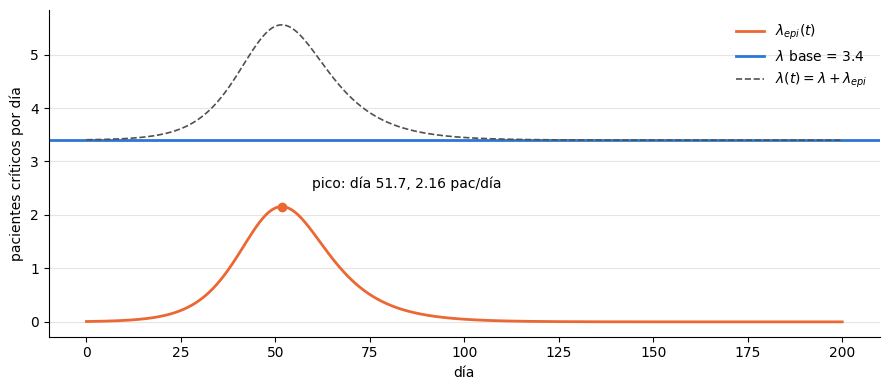

In [9]:
N, gamma, I0, p_h, Tsir = 500_000, 0.2, 100, 0.0002, 200.0

def sir_rk4(beta, gamma, N, I0, T, dt=0.05):
    """Integra el SIR con RK4 (método de la semana 3)."""
    n = int(round(T / dt)); t = np.arange(n + 1) * dt; Y = np.zeros((n + 1, 3)); Y[0] = [N - I0, I0, 0.0]
    f = lambda y: np.array([-beta * y[0] * y[1] / N, beta * y[0] * y[1] / N - gamma * y[1], gamma * y[1]])
    for i in range(n):
        y = Y[i]; k1 = f(y); k2 = f(y + dt / 2 * k1); k3 = f(y + dt / 2 * k2); k4 = f(y + dt * k3)
        Y[i + 1] = y + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return t, Y

ts, Y = sir_rk4(beta, gamma, N, I0, Tsir)
S_, I_, R_ = Y.T
lam_epi = p_h * beta * S_ * I_ / N                                   # tasa adicional de llegadas
ipk = lam_epi.argmax()
print(f"R0 = beta/gamma = {beta/gamma:.2f}")
print(f"Pico de lambda_epi: {lam_epi[ipk]:.3f} pac/día en el día {ts[ipk]:.1f}  (lambda total = {lam + lam_epi[ipk]:.3f})")
print(f"Pico de infectados: {I_.max():,.0f} en el día {ts[I_.argmax()]:.1f}; pacientes UCI adicionales totales: {np.trapezoid(lam_epi, ts):.1f}")
w_in, w_out = ts[lam_epi > 0.1][0], ts[lam_epi > 0.1][-1]
print(f"Ola (lambda_epi > 0.1 pac/día): días {w_in:.1f} a {w_out:.1f}")
C1, C2 = "#2a78d6", "#eb6834"
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ts, lam_epi, color=C2, lw=2, label=r"$\lambda_{epi}(t)$"); ax.axhline(lam, color=C1, lw=2, label=rf"$\lambda$ base = {lam}")
ax.plot(ts, lam + lam_epi, color="#52514e", lw=1.2, ls="--", label=r"$\lambda(t)=\lambda+\lambda_{epi}$")
ax.scatter([ts[ipk]], [lam_epi[ipk]], color=C2, zorder=5); ax.annotate(f"pico: día {ts[ipk]:.1f}, {lam_epi[ipk]:.2f} pac/día", (ts[ipk], lam_epi[ipk]), xytext=(ts[ipk] + 8, lam_epi[ipk] + 0.35))
ax.set_xlabel("día"); ax.set_ylabel("pacientes críticos por día"); ax.legend(frameon=False); ax.grid(axis="y", color="#e6e5e1")
for s_ in ("top", "right"): ax.spines[s_].set_visible(False)
plt.tight_layout(); plt.savefig("fig_lambda_epi.png", dpi=130); plt.show()

## Task 4.1b — Bloqueo en función del tiempo (sin espera, 100 réplicas)
Se usa `simulate3` con $\lambda(t)=\lambda+\lambda_{epi}(t)$ por adelgazamiento ($\lambda_{max}=\lambda+\max\lambda_{epi}$) y $c=c_{rec}$. El sistema arranca 60 días antes de $t=0$ con $\lambda$ base (estado casi estacionario). Ola = días con $\lambda_{epi}>0.1$.

In [10]:
lam_t = lambda t: lam + (np.interp(t, ts, lam_epi) if t >= 0 else 0.0)      # lambda(t) = lambda + lambda_epi(t)
lam_max = lam + lam_epi.max()
BW = 0.5; R4 = 100
w0, w1 = round(w_in * 2) / 2, round(w_out * 2) / 2                           # ventana de la ola alineada a bins de 0.5 d
i0, i1 = int(w0 / BW), int(w1 / BW)

def run_wave(cc, master_seed=2026, R=R4, **kw):
    A_, B_ = [], []
    for s in np.random.SeedSequence(master_seed).spawn(R):
        ar, bl = simulate3(lam_t, lam_max, cc, Tsir, t_start=-60.0, seed=s, bin_w=BW, **kw)
        A_.append(ar); B_.append(bl)
    return np.array(A_), np.array(B_)

# Prueba: el adelgazamiento reproduce la integral de lambda(t) (llegadas esperadas en la ventana)
A21, B21 = run_wave(c_rec)
esp = np.trapezoid(np.array([lam_t(t) for t in np.arange(w0, w1, 0.01)]), dx=0.01)
print(f"Llegadas en la ola [{w0},{w1}]: sim {A21[:, i0:i1].sum(1).mean():.1f} ± {ci95(A21[:, i0:i1].sum(1))[1]:.1f} | integral de lambda(t) = {esp:.1f}")

def wave_stats(A_, B_):
    desv = B_[:, i0:i1].sum(1); llegs = A_[:, i0:i1].sum(1)
    return ci95(desv), ci95(desv / llegs), desv, llegs
(dm, dh), (fm, fh), desv, llegs = wave_stats(A21, B21)
print(f"c = {c_rec}: desviados durante la ola = {dm:.1f} ± {dh:.1f}  | fracción desviada = {100*fm:.2f} % ± {100*fh:.2f} %  (de {llegs.mean():.0f} llegadas)")
print(f"Desviados en los 200 días: {ci95(B21.sum(1))[0]:.1f} ± {ci95(B21.sum(1))[1]:.1f}")

Llegadas en la ola [19.5,92.5]: sim 315.0 ± 3.7 | integral de lambda(t) = 315.5
c = 21: desviados durante la ola = 26.0 ± 2.4  | fracción desviada = 8.12 % ± 0.69 %  (de 315 llegadas)
Desviados en los 200 días: 32.9 ± 2.6


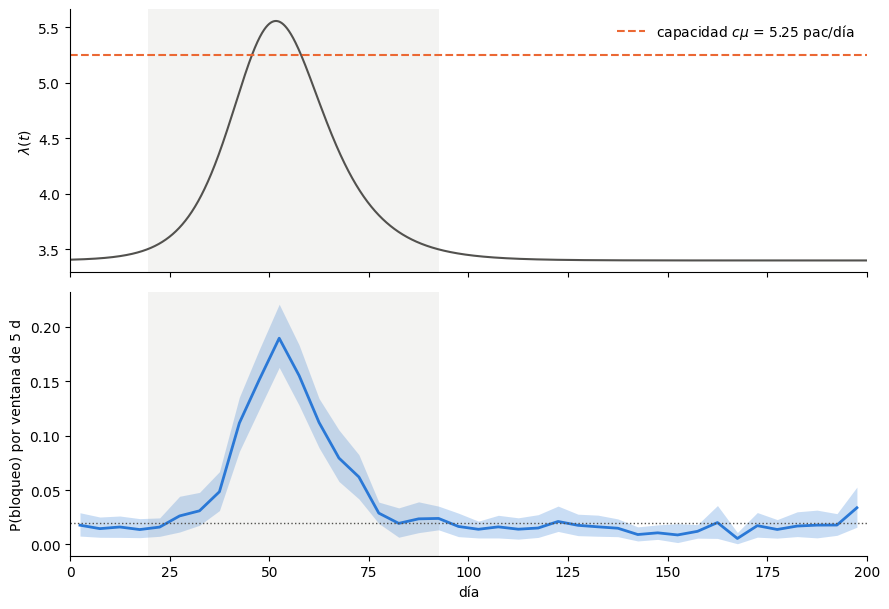

Pico de bloqueo por ventana de 5 d: 0.190 en el día 52.5


In [11]:
# Probabilidad de bloqueo por ventanas de 5 días (cociente de totales por réplica, IC bootstrap sobre réplicas)
agg = 10                                                                      # 10 bins de 0.5 d = 5 d
nbin = A21.shape[1] // agg
Ab = A21[:, :nbin * agg].reshape(R4, nbin, agg).sum(2); Bb = B21[:, :nbin * agg].reshape(R4, nbin, agg).sum(2)
rg = np.random.default_rng(1); pm = Bb.sum(0) / Ab.sum(0)
bs = np.array([ (Bb[ix].sum(0) / Ab[ix].sum(0)) for ix in (rg.integers(0, R4, R4) for _ in range(400))])
lo, hi = np.percentile(bs, [2.5, 97.5], axis=0); tc = (np.arange(nbin) + 0.5) * agg * BW
fig, ax = plt.subplots(2, 1, figsize=(9, 6.2), sharex=True)
ax[0].plot(ts, lam + lam_epi, color="#52514e", lw=1.5); ax[0].axhline(c_rec * mu, color=C2, ls="--", label=rf"capacidad $c\mu$ = {c_rec*mu:.2f} pac/día"); ax[0].set_ylabel(r"$\lambda(t)$"); ax[0].legend(frameon=False)
ax[1].fill_between(tc, lo, hi, color=C1, alpha=0.25, lw=0); ax[1].plot(tc, pm, color=C1, lw=2); ax[1].axhline(0.02, color="#52514e", ls=":", lw=1)
ax[1].set_ylabel("P(bloqueo) por ventana de 5 d"); ax[1].set_xlabel("día"); ax[1].set_xlim(0, Tsir)
for a_ in ax:
    a_.axvspan(w0, w1, color="#8a8a85", alpha=0.10, lw=0)
    for s_ in ("top", "right"): a_.spines[s_].set_visible(False)
plt.tight_layout(); plt.savefig("fig_bloqueo_tiempo.png", dpi=130); plt.show()
print("Pico de bloqueo por ventana de 5 d:", f"{pm.max():.3f}", "en el día", tc[pm.argmax()])

## Task 4.1c — Camas de contingencia para que la fracción desviada en la ola sea ≤ 5 %
Se repite la simulación con $c=c_{rec}+x$ (mismas semillas para comparar, números aleatorios comunes) hasta que la fracción desviada durante la ola no supere 5 %.

In [12]:
rows = []
for x in range(0, 9):
    A_, B_ = run_wave(c_rec + x)
    (dm_, dh_), (fm_, fh_), _, _ = wave_stats(A_, B_)
    rows.append(dict(camas=c_rec + x, extra=x, desviados_ola=dm_, desv_IC=dh_, fraccion=fm_, frac_IC=fh_, cumple_5pct=fm_ <= 0.05, IC_sup_cumple=fm_ + fh_ <= 0.05))
cont = pd.DataFrame(rows).set_index('camas'); display(cont.round(4))
x_min = int(cont[cont.cumple_5pct].extra.min()); print("Camas de contingencia mínimas (media <= 5 %):", x_min, "-> total", c_rec + x_min)

,extra,desviados_ola,desv_IC,fraccion,frac_IC,cumple_5pct,IC_sup_cumple
camas,,,,,,,
21,0,25.97,2.4013,0.0812,0.0069,False,False
22,1,19.79,2.0742,0.0617,0.0060,False,False
23,2,17.13,1.8104,0.0535,0.0052,False,False
24,3,12.60,1.5954,0.0391,0.0047,True,True
25,4,9.41,1.5261,0.0293,0.0046,True,True
26,5,6.40,1.1128,0.0200,0.0035,True,True
27,6,4.93,1.0887,0.0153,0.0033,True,True
28,7,3.15,0.7258,0.0098,0.0022,True,True
29,8,2.40,0.6839,0.0074,0.0021,True,True


Camas de contingencia mínimas (media <= 5 %): 3 -> total 24


## Task 4.1d — Sensibilidad ilustrativa a un fenómeno omitido
Se ilustra solo uno de los dos fenómenos del reporte: erosión de capacidad por personal contagiado (2 camas, ≈10 %, no operativas durante la ola). El otro (retroalimentación hacia la epidemia) se argumenta, no se simula.

In [13]:
A_e, B_e = run_wave(c_rec, closure=(w0, w1 - w0, 2))
(dm_e, dh_e), (fm_e, fh_e), _, _ = wave_stats(A_e, B_e)
print(f"Base      c={c_rec}: fracción desviada en la ola = {100*fm:.2f} % ± {100*fh:.2f} %, desviados = {dm:.1f}")
print(f"Menos 2 camas en la ola: fracción desviada = {100*fm_e:.2f} % ± {100*fh_e:.2f} %, desviados = {dm_e:.1f} ± {dh_e:.1f}")

Base      c=21: fracción desviada en la ola = 8.12 % ± 0.69 %, desviados = 26.0
Menos 2 camas en la ola: fracción desviada = 13.19 % ± 0.74 %, desviados = 42.0 ± 2.6
